# Logistics, Delivery & Returns Insights

**Capstone Option B | DataSense Analytics DASP Batch B02**
**Prepared by:** Cristine Angelica Marie Serrano Tolentino

**Business question:** How well are we delivering, and what causes returns?

**Data:** 7 CSV files (customers, products, orders, order_items, payments, shipments, returns) with 15,000 orders from January 2024 to January 2026.

**How this notebook is organized**
1. Setup
2. Load and first look
3. Data checks and cleaning (new `_clean` columns, the original columns are not changed, plus a cleaning log)
4. Analysis (delivery KPIs, couriers, returns, fact table)
5. Charts
6. Dashboard
7. Key insights and recommendations
8. Executive summary

## 1. Setup

In [1]:
#Libraries
import pandas as pd # Pandas for working with tables
import numpy as np # Numpy for math and missing values
import matplotlib.pyplot as plt # Matplotlib for charts,titles and saving PNGs
import seaborn as sns # seaborn makes the charts look cleaner
from pathlib import Path # Path for finding my folders

In [2]:
#Settings
pd.set_option("display.max_columns", None) # show all columns
pd.set_option("display.width", 200) # wider printout so it doesn't wrap
sns.set_theme(style="whitegrid") # clean chart style
plt.rcParams["figure.figsize"] = (10, 6) # default size

In [3]:
#Folders
RAW = Path("data_raw") # original files, I never edit these
CLEAN = Path("data_clean") # cleaned files go here
CHARTS = Path("charts") # chart PNGs go here

## 2. Load and first look

In [4]:
# Check that everything is found
print("pandas version:", pd.__version__)
print("seaborn version:", sns.__version__)
print("Raw folder exists:", RAW.exists())

# loop through the csv files in my raw folder and print each name
for f in RAW.glob("*.csv"):
    print(f.name)


pandas version: 3.0.5
seaborn version: 0.13.2
Raw folder exists: True
customers.csv
returns.csv
orders.csv
payments.csv
order_items.csv
shipments.csv
products.csv


In [5]:
# load the 7 csv files
# dtype=str keeps everything as text so Python doesn't change the messy values yet
# encoding="utf-8-sig" so the peso sign reads correctly
customers   = pd.read_csv(RAW / "customers.csv",   dtype=str, encoding="utf-8-sig") # who bought
products    = pd.read_csv(RAW / "products.csv",    dtype=str, encoding="utf-8-sig") # what we sell
orders      = pd.read_csv(RAW / "orders.csv",      dtype=str, encoding="utf-8-sig") # one row per order
order_items = pd.read_csv(RAW / "order_items.csv", dtype=str, encoding="utf-8-sig") # items inside each order
payments    = pd.read_csv(RAW / "payments.csv",    dtype=str, encoding="utf-8-sig") # how they paid
shipments   = pd.read_csv(RAW / "shipments.csv",   dtype=str, encoding="utf-8-sig") # courier, status, dates
returns     = pd.read_csv(RAW / "returns.csv",     dtype=str, encoding="utf-8-sig") # returned orders and reasons

In [6]:
#Put all 7 in one dictionary so I can loop through them
tables = {
    "customers": customers, "products": products, "orders": orders,
    "order_items": order_items, "payments": payments,
    "shipments": shipments, "returns": returns,
}

In [7]:
#Check the size of each table (rows, columns)
print("customers:", customers.shape)
print("products:", products.shape)
print("orders:", orders.shape)
print("order_items:", order_items.shape)
print("payments:", payments.shape)
print("shipments:", shipments.shape)
print("returns:", returns.shape)

customers: (5050, 13)
products: (800, 9)
orders: (15075, 8)
order_items: (37763, 5)
payments: (15000, 6)
shipments: (15000, 7)
returns: (1200, 6)


In [8]:
# checking the columns
print("ORDERS")
display(orders.head())

ORDERS


,order_id,customer_id,order_datetime,order_status,sales_channel,shipping_method,discount_pct,shipping_fee
0,ORD0000001,CUST000839,2025-11-07 17:02:00,Cancelled,Marketplace,Standard,0.074,102.68
1,ORD0000002,CUST002871,09/18/2025 09:13 AM,Completed,Marketplace,Express,0.063,0.0
2,ORD0000003,CUST000720,2025-08-08 04:59:00,Completed,Web,Standard,0.137,103.83
3,ORD0000004,CUST002515,2025-10-14 12:56:00,Completed,Web,Pickup,0.005,112.69
4,ORD0000005,CUST001544,2024-05-30 04:56:00,Completed,Marketplace,Pickup,NaN,111.73


In [9]:
print("SHIPMENTS")
display(shipments.head())

SHIPMENTS


,shipment_id,order_id,courier,tracking_no,shipment_status,ship_date,delivered_date
0,SHP0000001,ORD0000001,J&T,HLI2ORMO9V4O,Delivered,2025-09-05,09/06/2025
1,SHP0000002,ORD0000002,NinjaVan,E8XLRMV7QVEB,In Transit,2025-02-06,2025-02-12
2,SHP0000003,ORD0000003,2GO,LHLXVJF18MQB,Delivered,2025-07-23,2025-07-29
3,SHP0000004,ORD0000004,GrabExpress,RXUNTQ7WKL5B,Delivered,2025-01-21,2025-01-25
4,SHP0000005,ORD0000005,2GO,XQLUM80WBUSJ,In Transit,2025-09-21,2025-09-26


In [10]:
print("RETURNS")
display(returns.head())

RETURNS


,return_id,order_id,return_request_date,reason,refunded_flag,refund_amount
0,RET000001,ORD0008752,2025-01-09,Defective,No,NaN
1,RET000002,ORD0007359,2025-07-20,Wrong item,NaN,650.28
2,RET000003,ORD0009041,01/07/2025,Size issue,Yes,NaN
3,RET000004,ORD0000227,2025-03-04,Late delivery,Partial,NaN
4,RET000005,ORD0005754,2025-04-24,Size issue,Yes,713.39


In [11]:
print("PRODUCTS")
display(products.head())

PRODUCTS


,product_id,product_name,brand,category,unit_cost,unit_price,stock_qty,uom,launch_date
0,PROD00001,KidJoy Beauty 963,KidJoy,Beauty,44.17,64.5,125.0,pc,2022-01-18
1,PROD00002,HomeEase Home 368,HomeEase,Home and Kitchen,37.18,70.39,131.0,pcs,2022-11-25
2,PROD00003,FreshCart Fashion 911,FreshCart,Fashion,46.29,₱70.26,41.0,piece,2023-09-04
3,PROD00004,NovaTech Toys 753,NovaTech,Toys,43.66,62.46,149.0,pcs,2023-08-12
4,PROD00005,GlowCo Books 916,GlowCo,Books,64.59,82.02,162.0,bottle,2024-05-12


## 3. Data checks and cleaning

### 3.1 Duplicates and blanks

In [12]:
# count duplicate rows in each table
print("customers duplicates:", customers.duplicated().sum())
print("products duplicates:", products.duplicated().sum())
print("orders duplicates:", orders.duplicated().sum())
print("order_items duplicates:", order_items.duplicated().sum())
print("payments duplicates:", payments.duplicated().sum())
print("shipments duplicates:", shipments.duplicated().sum())
print("returns duplicates:", returns.duplicated().sum())

customers duplicates: 50
products duplicates: 0
orders duplicates: 75
order_items duplicates: 262
payments duplicates: 0
shipments duplicates: 0
returns duplicates: 0


In [13]:
#Count missing values (blanks) in the main tables
print("ORDERS")
print(orders.isna().sum())

print("SHIPMENTS")
print(shipments.isna().sum())

print("RETURNS")
print(returns.isna().sum())

print("PRODUCTS")
print(products.isna().sum())

print("ORDER_ITEMS")
print(order_items.isna().sum())

ORDERS
order_id             0
customer_id          0
order_datetime       0
order_status         0
sales_channel        0
shipping_method      0
discount_pct       758
shipping_fee       474
dtype: int64
SHIPMENTS
shipment_id          0
order_id             0
courier              0
tracking_no          0
shipment_status      0
ship_date            0
delivered_date     729
dtype: int64
RETURNS
return_id                0
order_id                 0
return_request_date      0
reason                   0
refunded_flag          110
refund_amount          187
dtype: int64
PRODUCTS
product_id       0
product_name     0
brand            0
category         0
unit_cost        0
unit_price       0
stock_qty       19
uom              0
launch_date      0
dtype: int64
ORDER_ITEMS
order_item_id                0
order_id                     0
product_id                   0
quantity                     0
unit_price_at_purchase    2262
dtype: int64


In [14]:
#Remove duplicate rows (all columns identical, keep the first one)
# I print the rows before and after for each table so I can see how many were removed

# customers
before = len(customers)
customers = customers.drop_duplicates().reset_index(drop=True)
print("customers:", before, "->", len(customers))

# orders
before = len(orders)
orders = orders.drop_duplicates().reset_index(drop=True)
print("orders:", before, "->", len(orders))

# order_items
before = len(order_items)
order_items = order_items.drop_duplicates().reset_index(drop=True)
print("order_items:", before, "->", len(order_items))


customers: 5050 -> 5000
orders: 15075 -> 15000


order_items: 37763 -> 37501


### 3.2 Dates

In [15]:
# fix the mixed date formats
# format="mixed" lets pandas read each date in its own style
# I keep the original column and make a new _clean column next to it
orders["order_datetime_clean"] = pd.to_datetime(orders["order_datetime"], format="mixed")
shipments["ship_date_clean"] = pd.to_datetime(shipments["ship_date"], format="mixed")
shipments["delivered_date_clean"] = pd.to_datetime(shipments["delivered_date"], format="mixed")
returns["return_request_date_clean"] = pd.to_datetime(returns["return_request_date"], format="mixed")

In [16]:
#checking how many dates are blank after cleaning, blank dates show as NaT
print("orders order_datetime_clean blanks:", orders["order_datetime_clean"].isna().sum())
print("shipments ship_date_clean blanks:",  shipments["ship_date_clean"].isna().sum())
print("shipments delivered_date_clean:", shipments["delivered_date_clean"].isna().sum())
print("returns return_request_date_clean:", returns["return_request_date_clean"].isna().sum())

orders order_datetime_clean blanks: 0
shipments ship_date_clean blanks: 0
shipments delivered_date_clean: 729
returns return_request_date_clean: 0


In [17]:
# check earliest and latest order date
print("orders from", orders["order_datetime_clean"].min(), "to", orders["order_datetime_clean"].max())

orders from 2024-01-01 01:17:00 to 2026-01-31 23:36:00


### 3.3 Product categories and prices

In [18]:
# look at the category column first before fixing anything
# value_counts(), counts how many times each spelling shows up
print(products["category"].value_counts())

category
Beauty              94
Toys                92
Books               90
Fashion             89
Groceries           77
Home & Kitchen      76
Sports              74
Electronics         71
electronics         20
Book                20
Home and Kitchen    19
Electronics         17
Grocery             12
Elec                11
Beauty & Care       11
Toy                 11
Fashon               8
Sports & Outdoor     8
Name: count, dtype: int64


In [19]:
# nunique() counts how many different spellings there are
# I expect 8 categories, so anything more means messy spellings
print("different spellings:", products["category"].nunique())

different spellings: 18


In [20]:
# fix the category spellings
# strip () removes extra spaces and lower() makes everything lowercase
clean_text = products["category"].str.strip().str.lower()

In [21]:
# checking the unique() shows the different spellings, no counts
print(products["category"].unique())

<StringArray>
[          'Beauty', 'Home and Kitchen',          'Fashion',             'Toys',            'Books',           'Fashon',        'Groceries',      'electronics',           'Sports',
      'Electronics',          'Grocery',     'Electronics ',   'Home & Kitchen',             'Elec',    'Beauty & Care',              'Toy',             'Book', 'Sports & Outdoor']
Length: 18, dtype: str


In [22]:
# my dictionary, the old spelling on the left and the correct name on the right
category_map = {
    "electronics": "Electronics", "elec": "Electronics",
    "books": "Books", "book": "Books",
    "fashion": "Fashion", "fashon": "Fashion",
    "toys": "Toys", "toy": "Toys",
    "groceries": "Groceries", "grocery": "Groceries",
    "home & kitchen": "Home & Kitchen", "home and kitchen": "Home & Kitchen",
    "beauty": "Beauty", "beauty & care": "Beauty",
    "sports": "Sports", "sports & outdoor": "Sports",
}

In [23]:
# Map () swaps each old spelling for the correct name
products["category_clean"] = clean_text.map(category_map)

In [24]:
# checking the result
print(products["category_clean"].value_counts())

category_clean
Electronics       119
Books             110
Beauty            105
Toys              103
Fashion            97
Home & Kitchen     95
Groceries          89
Sports             82
Name: count, dtype: int64


In [25]:
# so 0 blanks means i covered every spelling
print("blanks:", products["category_clean"].isna().sum())

blanks: 0


In [26]:
# count the prices that have a peso sign in them
print("rows with peso sign:", products["unit_price"].str.contains("₱").sum())

rows with peso sign: 68


In [27]:
# show a few of them
print(products[products["unit_price"].str.contains("₱")]["unit_price"].head())

2      ₱70.26
7     ₱124.98
10    ₱127.26
12     ₱76.62
16    ₱109.58
Name: unit_price, dtype: str


In [28]:
# clean the prices, i do it in 3 small steps

# step 1 : remove the peso sign
price_text  = products["unit_price"].str.replace("₱", "")

In [29]:
# step 2: remove commas in case price looks like 1,234.56
price_text = price_text.str.replace(",", "")

In [30]:
# step 3: to numeric() turns the text into real numbers so i  can do math
products["unit_price_clean"] = pd.to_numeric(price_text)

In [31]:
# unit_cost has no peso signs but it is also stored as text, so i turn it into numbers too
products["unit_cost_clean"] = pd.to_numeric(products["unit_cost"].str.replace(",", ""))

In [32]:
# checking the new column should be numbers (float64) with 0 blanks
print(products["unit_price_clean"].dtype)
print("blanks:", products["unit_price_clean"].isna().sum())

float64
blanks: 0


In [33]:
# before and after for the first 5 rows
display(products[["unit_price", "unit_price_clean"]].head())

,unit_price,unit_price_clean
0,64.5,64.50
1,70.39,70.39
2,₱70.26,70.26
3,62.46,62.46
4,82.02,82.02


### 3.4 Shipments and lead time

In [34]:
# check the shipment status values
print(shipments["shipment_status"].value_counts())

shipment_status
Delivered             11680
In Transit             2694
Returned to Sender      465
Lost                    161
Name: count, dtype: int64


In [35]:
print(shipments["courier"].value_counts())

courier
J&T            3042
GrabExpress    3011
LBC            3011
NinjaVan       2985
2GO            2951
Name: count, dtype: int64


In [36]:
# count shipments by status and by whether they have a delivered date, IF True means the delivered date is blank
print(pd.crosstab(shipments["shipment_status"], shipments["delivered_date_clean"].isna()))

delivered_date_clean  False  True 
shipment_status                   
Delivered             11122    558
In Transit             2557    137
Lost                    151     10
Returned to Sender      441     24


In [37]:
# Lead time = delivered date minus ship date
# subtracting two dates gives a time difference, .dt.days turns it into a plain number of days
shipments["lead_time_days"] = (shipments["delivered_date_clean"] - shipments["ship_date_clean"]).dt.days

In [38]:
# Only delivered shipments should have a lead time
# where() keeps the value if the condition is True and leaves a blank if it is False
shipments["lead_time_days"] = shipments["lead_time_days"].where(shipments["shipment_status"] == "Delivered")

In [39]:
# How many shipments have a lead time
print("shipments with lead time:", shipments["lead_time_days"].notna().sum())

shipments with lead time: 11122


In [40]:
# describe () gives count, average, min and max in one go
print(shipments["lead_time_days"].describe())

count    11122.000000
mean         4.003507
std          1.993129
min          1.000000
25%          2.000000
50%          4.000000
75%          6.000000
max          7.000000
Name: lead_time_days, dtype: float64


In [41]:
# how many shipments for each lead time, sorted from 1 day up
print(shipments["lead_time_days"].value_counts().sort_index())

lead_time_days
1.0    1583
2.0    1573
3.0    1563
4.0    1630
5.0    1615
6.0    1592
7.0    1566
Name: count, dtype: int64


### 3.5 Orphans (keys that do not match another table)

In [42]:
# counting the orphans meaning a key that points to something that does not exist in the other table
# orders with a customer_id that is not in the customers table
print("orders with unknown customer:", (~orders["customer_id"].isin(customers["customer_id"])).sum())

orders with unknown customer: 43


In [43]:
# order_items with a product_id that is not in the product table
print("order_items with unknown product:", (~order_items["product_id"].isin(products["product_id"])).sum())

order_items with unknown product: 129


In [44]:
# order_items with an order_id that is not in the order table
print("order_items with unknown order:", (~order_items["order_id"].isin(orders["order_id"])).sum())

order_items with unknown order: 0


In [45]:
#shipments, returns and payments with an order_id that is not in the orders table
print("shipments with unknown order:", (~shipments["order_id"].isin(orders["order_id"])).sum())
print("returns with unknown order:", (~returns["order_id"].isin(orders["order_id"])).sum())
print("payments with unknown order:", (~payments["order_id"].isin(orders["order_id"])).sum())

shipments with unknown order: 0
returns with unknown order: 0
payments with unknown order: 0


In [46]:
# show which keys are the orphans 
# first i keep only the orphan rows, then i look at the different keys in them
print(orders[~orders["customer_id"].isin(customers["customer_id"])]["customer_id"].unique())
print(order_items[~order_items["product_id"].isin(products["product_id"])]["product_id"].unique())

<StringArray>
['CUST999999']
Length: 1, dtype: str
<StringArray>
['PROD00000']
Length: 1, dtype: str


In [47]:
# I flag the orphans in new columns and instead of deleting the rows
# True means the key was not found in the other table
orders["customer_orphan"] = ~orders["customer_id"].isin(customers["customer_id"])
order_items["product_orphan"] = ~order_items["product_id"].isin(products["product_id"])

In [48]:
# checking, 43 for customer orphan and 129 for product orphan
print(orders["customer_orphan"].sum(), order_items["product_orphan"].sum())

43 129


### 3.6 Before and after

In [49]:
# before and after side by side, I only show rows that were messy
# categories that changed
display(products[products["category"] != products["category_clean"]][["category", "category_clean"]].head(5))

,category,category_clean
1,Home and Kitchen,Home & Kitchen
7,Fashon,Fashion
11,electronics,Electronics
12,Home and Kitchen,Home & Kitchen
22,Grocery,Groceries


In [50]:
# prices that had a peso sign
display(products[products["unit_price"].str.contains("₱")][["unit_price", "unit_price_clean"]].head(3))

,unit_price,unit_price_clean
2,₱70.26,70.26
7,₱124.98,124.98
10,₱127.26,127.26


In [51]:
# order dates that were in the slash style
display(orders[orders["order_datetime"].str.contains("/")][["order_datetime", "order_datetime_clean"]].head(3))

,order_datetime,order_datetime_clean
1,09/18/2025 09:13 AM,2025-09-18 09:13:00
7,03/25/2024 10:47 AM,2024-03-25 10:47:00
17,02/25/2024 03:07 AM,2024-02-25 03:07:00


In [52]:
# delivered dates that were in the slash style
#na=False means a blank date count as "no", so it does not cause an error
display(shipments[shipments["delivered_date"].str.contains("/", na=False)][["delivered_date", "delivered_date_clean"]].head(3))

,delivered_date,delivered_date_clean
0,09/06/2025,2025-09-06
9,12/14/2024,2024-12-14
12,11/09/2025,2025-11-09


### 3.7 Remaining blanks, order items, orders, returns and products

In [53]:
# checking the size of each table since i forgot to show it in the beginning, first number is rows and second is columns
print("customer:", customers.shape)
print("products:", products.shape)
print("orders:", orders.shape)
print("order_items:", order_items.shape)
print("payments:", payments.shape)
print("shipments:", shipments.shape)
print("returns:", returns.shape)

customer: (5000, 13)
products: (800, 12)
orders: (15000, 10)
order_items: (37501, 6)
payments: (15000, 6)
shipments: (15000, 10)
returns: (1200, 7)


In [54]:
# count the blanks in the columns i have not cleaned yet
print("ORDERS")
print(orders[["discount_pct", "shipping_fee"]].isna().sum())

ORDERS
discount_pct    756
shipping_fee    470
dtype: int64


In [55]:
print("ORDER_ITEMS")
print(order_items[["quantity", "unit_price_at_purchase"]].isna().sum())

ORDER_ITEMS
quantity                     0
unit_price_at_purchase    2236
dtype: int64


In [56]:
print("RETURNS")
print(returns[["refunded_flag", "refund_amount"]].isna().sum())

RETURNS
refunded_flag    110
refund_amount    187
dtype: int64


In [57]:
print("PRODUCTS")
print(products[["stock_qty"]].isna().sum())

PRODUCTS
stock_qty    19
dtype: int64


In [58]:
# looking for invalid values
#quantity is still text, so I compare with "0" in quotes
print("rows with quantity 0:", (order_items["quantity"] =="0").sum())

rows with quantity 0: 372


In [59]:
# peso signs hiding in the order_items prices
print("prices with a peso sign:", order_items["unit_price_at_purchase"].str.contains("₱", na=False).sum())

prices with a peso sign: 3017


In [60]:
# The different values of refunded_flag dropna=False also counts the blanks
print(returns["refunded_flag"].value_counts(dropna=False))

refunded_flag
Yes        653
No         301
Partial    136
NaN        110
Name: count, dtype: int64


In [61]:
# remove the order lines with quantity 0, an order line cannot have 0 items
# I keep only the rows where quantity is NOT "0"
order_items = order_items[order_items["quantity"] != "0"].reset_index(drop=True)

# Make a number version of quantity so I can do math later
order_items["quantity_clean"] = pd.to_numeric(order_items["quantity"])

# checking
print(order_items.shape)
print(order_items["quantity_clean"].min(), order_items["quantity_clean"].max())

(37129, 7)
1 10


In [62]:
# clean the prices, same recipe as products: remove the peso sign and commas, then turn into numbers
price_text = order_items["unit_price_at_purchase"].str.replace("₱", "").str.replace(",", "")
order_items["unit_price_at_purchase_clean"] = pd.to_numeric(price_text)

In [63]:
# some prices are blank, so first I mark which ones were blank before I fill them
# True means the price was blank in the original file
order_items["price_was_blank"] = order_items["unit_price_at_purchase_clean"].isna()

# this is my lookup table, it works like a VLOOKUP in Excel: product_id on the left and the catalog price on the right
price_lookup = products.set_index("product_id")["unit_price_clean"]

# map() is the VLOOKUP, it finds the catalog price of each product_id, fillna() uses it only where the price is blank
order_items["unit_price_at_purchase_clean"] = order_items["unit_price_at_purchase_clean"].fillna(order_items["product_id"].map(price_lookup))

In [64]:
# checking, how many were blank and how many are still blank after filling
print("prices that were blank:", order_items["price_was_blank"].sum())
print("blanks left after filling:", order_items["unit_price_at_purchase_clean"].isna().sum())

prices that were blank: 2217
blanks left after filling: 9


In [65]:
# evidence that filling with the catalog price is safe
# I keep only the rows where the price was NOT blank and the product is NOT an orphan
# == False means "is not", I compare their price with the catalog price
check = order_items[(order_items["price_was_blank"] == False) & (order_items["product_orphan"] == False)]
same = check["unit_price_at_purchase_clean"] == check["product_id"].map(price_lookup)
print("rows with the same price as the catalog:", same.sum(), "out of", len(same))

rows with the same price as the catalog: 34794 out of 34794


In [66]:
# orders that lost all their order lines after removing quantity 0
# isin() checks if the order_id is found in order_items, ~ flips it to "not found"
print("orders with no order lines:", (~orders["order_id"].isin(order_items["order_id"])).sum())

orders with no order lines: 23


In [67]:
# these columns are text right now, so I make number versions to do math later
#if any value was not a number, to_numeric() would show an error, so no error means they are clean
# blanks stay blank because I do not know the real value

# orders
orders["discount_pct_clean"] = pd.to_numeric(orders["discount_pct"])
orders["shipping_fee_clean"] = pd.to_numeric(orders["shipping_fee"])

#returns
returns["refund_amount_clean"] = pd.to_numeric(returns["refund_amount"])

# products
products["stock_qty_clean"] = pd.to_numeric(products["stock_qty"])

In [68]:
# fillna() put a value only where the cell is blank
# I use "Unknown" because I cannot guess if the refund was Yes, No or Partial
returns["refunded_flag_clean"] = returns["refunded_flag"].fillna("Unknown")

In [69]:
# merge the unit of measure spellings
# pc, pcs and piece mean the same thing, same recipe as my category fix
uom_map = {"pc": "pc", "pcs": "pc", "piece": "pc", "pack": "pack", "bottle": "bottle", "set": "set"}
products["uom_clean"] = products["uom"].str.strip().str.lower().map(uom_map)

In [70]:
# dtype should be float64, and the blanks should be the same as before
print(orders["discount_pct_clean"].dtype, orders["discount_pct_clean"].isna().sum())
print(orders["shipping_fee_clean"].dtype, orders["shipping_fee_clean"].isna().sum())
print(returns["refund_amount_clean"].dtype, returns["refund_amount_clean"].isna().sum())
print(products["stock_qty_clean"].dtype, products["stock_qty_clean"].isna().sum())
print(returns["refunded_flag_clean"].value_counts())
print(products["uom_clean"].value_counts(dropna=False))
print(orders.shape, returns.shape, products.shape)

float64 756
float64 470
float64 187
float64 19
refunded_flag_clean
Yes        653
No         301
Partial    136
Unknown    110
Name: count, dtype: int64
uom_clean
pc        429
pack      125
bottle    123
set       123
Name: count, dtype: int64
(15000, 12) (1200, 9) (800, 14)


### 3.8 Customers

In [71]:
# Customers cleanup (gender, age, loyalty tier)
# look at the gender column before fixing anything
#dropna=False also counts the blanks
print(customers["gender"].value_counts(dropna=False))

gender
M          1297
F          1263
Female      721
Male        719
Unknown     587
NaN         298
female      115
Name: count, dtype: int64


In [72]:
# for gender
# my dictionary, the old spelling on the left and the correct word on the right
# the left side is all lowercase because I lower() the text first
gender_map = {"m": "Male", "male": "Male", "f": "Female", "female": "Female", "unknown": "Unknown"}

In [73]:
#strip() remove spaces, lower() make it lowercase, map() swaps it using my dictionary
# blanks are not in the dictionary, so fillna() turns them into unknown
customers["gender_clean"] = customers["gender"].str.strip().str.lower().map(gender_map).fillna("Unknown")

In [74]:
#checking 
print(customers["gender_clean"].value_counts(dropna=False))

gender_clean
Female     2099
Male       2016
Unknown     885
Name: count, dtype: int64


In [75]:
# for age
# age is still text, so I make a number version first
customers["age_clean"] = pd.to_numeric(customers["age"])

In [76]:
# look at the smallest and biggest values, describe() shows count, average, min and max
print(customers["age_clean"].describe())
print("blank ages:", customers["age_clean"].isna().sum())
print("negative ages:", (customers["age_clean"] <0).sum())
print("age under 13:", (customers["age_clean"] <13).sum())
print("ages over 100:", (customers["age_clean"] > 100).sum())

count    4851.000000
mean       31.199753
std        10.587110
min        -5.000000
25%        24.000000
50%        32.000000
75%        38.000000
max        65.000000
Name: age_clean, dtype: float64
blank ages: 149
negative ages: 48
age under 13: 203
ages over 100: 0


In [77]:
# my rule, an age from 13 to 100 is believable for a customer, anything else i make blank
# & means "and", and each condition needs its own brackets
good_age = (customers["age_clean"] >= 13) & (customers["age_clean"] <= 100)

# where() keeps the value when the condition is True and makes it blank when it is False
customers["age_clean"] = customers["age_clean"].where(good_age)

In [78]:
# checking, 149 were blank before and 203 more became blank, so 352 in total
print("blanks now:", customers["age_clean"].isna().sum())
print(customers["age_clean"].min(), customers["age_clean"].max())

blanks now: 352
13.0 65.0


In [79]:
# for loyalty tier
# look fix and check
# the blank tiers become unknown, the real tiers stay the same
print(customers["loyalty_tier"].value_counts(dropna=False))

customers["loyalty_tier_clean"] = customers["loyalty_tier"].fillna("Unknown")

# checking
print(customers["loyalty_tier_clean"].value_counts())

loyalty_tier
Bronze      2204
Silver      1257
Gold         915
Platinum     360
NaN          264
Name: count, dtype: int64
loyalty_tier_clean
Bronze      2204
Silver      1257
Gold         915
Platinum     360
Unknown      264
Name: count, dtype: int64


In [80]:
# for email
# a good email has an @ and ends with .com or .ph, so I check those 2 things
has_at = customers["email"].str.contains("@", na=False)
ends_ok = customers["email"].str.endswith(".com", na=False) | customers["email"].str.endswith(".ph", na=False)

# a good email needs both, & means "and"
customers["email_valid"] = has_at & ends_ok

In [81]:
# wrong emails = not valid and not blank, dropna() removes the blank ones
wrong = customers[customers["email_valid"] == False]["email"].dropna()
print(wrong.head())
print("blank emails:", customers["email"].isna().sum())
print("wrong emails:", len(wrong))
print("good emails:", customers["email_valid"].sum())

2      arvin.navarrooutlook.com
11         jasmineramos@mailcom
60        juancastillo@gmailcom
80          marksantos@yahoocom
83    maria.castillooutlook.com
Name: email, dtype: str
blank emails: 104
wrong emails: 225
good emails: 4671


In [82]:
# I do not guess the missing @ or dot, so a wrong email becomes blank in the clean column
customers["email_clean"] = customers["email"].where(customers["email_valid"])
print("blank emails now:", customers["email_clean"].isna().sum())

blank emails now: 329


In [83]:
# for phone
# phone numbers should have 11 digits and start with 09, like 09196001338
# str.len() counts the characters
print(customers["phone"].str.len().value_counts(dropna=False))

phone
11.0    4722
NaN      145
10.0     133
Name: count, dtype: int64


In [84]:
# my rule: a good phone has 11 digits and starts with 09
# the first part checks the length, startswith() checks the start, & means "and"
customers["phone_valid"] = (customers["phone"].str.len() == 11) & customers["phone"].str.startswith("09", na=False)

# short or blank phones become blank in the clean column
customers["phone_clean"] = customers["phone"].where(customers["phone_valid"])

# checking
print("good phones:", customers["phone_valid"].sum())
print("short phones made blank:", (customers["phone"].str.len() == 10).sum())
print("blank phones now:", customers["phone_clean"].isna().sum())

good phones: 4722
short phones made blank: 133
blank phones now: 278


In [85]:
# for signup date
# I print the first 20 to see the different styles: 2025-12-31, 09/04/2024 and 09-Aug-2025
print(customers["signup_date"].head(20))

0      2025-12-31
1      2025-02-08
2      2023-09-10
3      2024-11-17
4      2023-01-21
5      2025-08-13
6      2025-10-22
7      2025-09-22
8      2025-12-12
9      2024-06-04
10     2023-10-16
11     2025-11-22
12     09/04/2024
13     2025-05-13
14     06/24/2024
15     2023-07-09
16     2024-12-10
17     2024-03-17
18    09-Aug-2025
19     2025-12-12
Name: signup_date, dtype: str


In [86]:
# same recipe as my other dates
# a date like 06/24/2024 can only be June 24, there is no month 24, so the slash style is month first
customers["signup_date_clean"] = pd.to_datetime(customers["signup_date"], format="mixed")

# checking
print("blanks:", customers["signup_date_clean"].isna().sum())
print(customers["signup_date_clean"].min(), customers["signup_date_clean"].max())
display(customers[customers["signup_date"].str.contains("/")][["signup_date", "signup_date_clean"]].head(3))

blanks: 0
2023-01-01 00:00:00 2026-01-31 00:00:00


,signup_date,signup_date_clean
12,09/04/2024,2024-09-04
14,06/24/2024,2024-06-24
27,09/11/2023,2023-09-11


### 3.9 Payments

In [87]:
# payments is the one table I have not cleaned yet, so I look at it first
print("amounts with a peso sign:", payments["amount_paid"].str.contains("₱", na=False).sum())
print("amounts with a comma:", payments["amount_paid"].str.contains(",", na=False).sum())
print("blank amounts:", payments["amount_paid"].isna().sum())
print("dates in the slash style:", payments["payment_date"].str.contains("/").sum())

amounts with a peso sign: 556
amounts with a comma: 386
blank amounts: 878
dates in the slash style: 2260


In [88]:
# same recipe as my products prices: remove the peso sign and commas, then turn into numbers
amount_text = payments["amount_paid"].str.replace("₱", "").str.replace(",", "")
payments["amount_paid_clean"] = pd.to_numeric(amount_text)

# same recipe as my other dates
# a date like 06/25/2024 can only be June 25, there is no month 25, so the slash style is month first
payments["payment_date_clean"] = pd.to_datetime(payments["payment_date"], format="mixed")

In [89]:
print(payments["amount_paid_clean"].dtype)
print("blank amounts:", payments["amount_paid_clean"].isna().sum())
print("amounts that are 0:", (payments["amount_paid_clean"] == 0).sum())
print("blank dates:", payments["payment_date_clean"].isna().sum())
print(payments["payment_date_clean"].min(), payments["payment_date_clean"].max())
display(payments[payments["amount_paid"].str.contains("₱", na=False)][["amount_paid", "amount_paid_clean"]].head(3))

float64
blank amounts: 878
amounts that are 0: 657
blank dates: 0
2024-01-01 00:00:00 2026-01-31 00:00:00


,amount_paid,amount_paid_clean
7,"₱2,250.92",2250.92
33,₱30.76,30.76
39,₱830.33,830.33


### 3.10 Data checks (limitations I found)

In [90]:
# data checking shipments vs order date
# I look up the order date of each shipment, it works like a VLOOKUP in Excel
# normalize() keeps only the date and sets the time to 00:00, so I can compare it with the ship date
order_date = orders.set_index("order_id")["order_datetime_clean"].dt.normalize()
ship_order_date = shipments["order_id"].map(order_date)

print("shipments shipped before the order date:", (shipments["ship_date_clean"] < ship_order_date).sum())
print("shipments shipped on the order date:", (shipments["ship_date_clean"] == ship_order_date).sum())

shipments shipped before the order date: 7397
shipments shipped on the order date: 21


In [91]:
# returns vs order date
# same idea for the returns, a return should not be requested before the order
return_order_date = returns["order_id"].map(order_date)
print("returns requested before the order date:", (returns["return_request_date_clean"] < return_order_date).sum())

returns requested before the order date: 583


In [92]:
# refund flag vs refund amount
# a refunded_flag of No should not have a refund amount, and Yes should have one
print("refunded_flag No but has a refund amount:", ((returns["refunded_flag"] == "No") & returns["refund_amount_clean"].notna()).sum())
print("refunded_flag Yes but no refund amount:", ((returns["refunded_flag"] == "Yes") & returns["refund_amount_clean"].isna()).sum())

refunded_flag No but has a refund amount: 248
refunded_flag Yes but no refund amount: 99


In [93]:
# count returns
# is there only one return per order? this decides how I count the return rate
print("returns:", len(returns), "different orders:", returns["order_id"].nunique())

# does the order status say Returned for the orders in my returns table?
print(returns["order_id"].map(orders.set_index("order_id")["order_status"]).value_counts())

returns: 1200 different orders: 1200
order_id
Completed    814
Shipped      145
Pending      116
Cancelled     85
Returned      40
Name: count, dtype: int64


### 3.11 Cleaning log

In [94]:
# rebuild my cleaning log from scratch
# I start with an empty list, so this cell is safe to run again and no line repeats
# when I clean more tables later, I add the new lines inside this cell
cleaning_log = []

# duplicates
cleaning_log.append(["customers", "Removed duplicate rows", 5050, 5000])
cleaning_log.append(["orders", "Removed duplicate rows", 15075, 15000])
cleaning_log.append(["order_items", "Removed duplicate rows", 37763, 37501])
cleaning_log.append(["products", "Checked duplicates, none found", 800, 800])
cleaning_log.append(["shipments", "Checked duplicates, none found", 15000, 15000])
cleaning_log.append(["returns", "Checked duplicates, none found", 1200, 1200])
cleaning_log.append(["payments", "Checked duplicates, none found", 15000, 15000])

# dates, categories and prices
cleaning_log.append(["orders", "Parsed mixed dates into order_datetime_clean", 15000, 15000])
cleaning_log.append(["shipments", "Parsed mixed dates into ship_date_clean and delivered_date_clean", 15000, 15000])
cleaning_log.append(["returns", "Parsed mixed dates into return_request_date_clean", 1200, 1200])
cleaning_log.append(["products", "Standardized 18 category spellings into 8 (category_clean)", 800, 800])
cleaning_log.append(["products", "Removed peso signs and commas, made unit_price and unit_cost numbers (_clean columns)", 800, 800])

# lead time rule and orphans
cleaning_log.append(["shipments", "Lead time only for Delivered shipments, 3149 other shipments had delivered dates that cannot be trusted", 15000, 15000])
cleaning_log.append(["orders", "Flagged 43 orders with unknown customer CUST999999 (customer_orphan), kept for delivery and returns analysis", 15000, 15000])
cleaning_log.append(["order_items", "Flagged 129 items with unknown product PROD00000 (product_orphan), left out of category analysis only", 37501, 37501])

# order_items quantity and prices
cleaning_log.append(["order_items", "Removed 372 order lines with quantity 0 and made quantity_clean (2 of them were product orphans, so 127 orphan items remain)", 37501, 37129])
cleaning_log.append(["order_items", "Removed peso signs and commas in unit_price_at_purchase (unit_price_at_purchase_clean)", 37129, 37129])
cleaning_log.append(["order_items", "Filled 2217 blank prices with the catalog price of the same product (price_was_blank marks them), 9 stay blank because the product is unknown. Non blank prices matched the catalog 100 percent", 37129, 37129])
cleaning_log.append(["orders", "23 orders have no order lines left after the quantity 0 removal, kept for delivery and returns analysis", 15000, 15000])

# remaining blanks
cleaning_log.append(["orders", "Made discount_pct and shipping_fee numbers (_clean columns), 756 and 470 blanks kept as blank, not guessed", 15000, 15000])
cleaning_log.append(["returns", "Made refund_amount a number (refund_amount_clean), 187 blanks kept as blank", 1200, 1200])
cleaning_log.append(["returns", "Filled 110 blank refunded_flag with Unknown (refunded_flag_clean)", 1200, 1200])
cleaning_log.append(["products", "Made stock_qty a number (stock_qty_clean, 19 blanks kept) and merged pc, pcs, piece into pc (uom_clean)", 800, 800])

# customers
cleaning_log.append(["customers", "Standardized gender (M, F, Male, Female, female, blank) into Male, Female, Unknown (gender_clean)", 5000, 5000])
cleaning_log.append(["customers", "Made age a number (age_clean), 203 ages under 13 (48 of them negative) set to blank, 149 were already blank", 5000, 5000])
cleaning_log.append(["customers", "Filled 264 blank loyalty_tier with Unknown (loyalty_tier_clean)", 5000, 5000])
cleaning_log.append(["customers", "Checked emails, 225 wrong ones (missing @ or dot) and 104 blanks, email_clean keeps only good emails and email_valid shows which ones are good", 5000, 5000])
cleaning_log.append(["customers", "Checked phones, 133 short numbers made blank in phone_clean (phone_valid marks the good ones, 11 digits starting with 09), 145 were already blank", 5000, 5000])
cleaning_log.append(["customers", "Parsed 3 mixed signup_date styles into signup_date_clean (slash dates read as month first)", 5000, 5000])

# payments
cleaning_log.append(["payments", "Removed peso signs and commas in amount_paid and made it a number (amount_paid_clean), 878 blanks kept as blank, 657 amounts are 0 and kept as they are", 15000, 15000])
cleaning_log.append(["payments", "Parsed mixed payment_date into payment_date_clean (slash dates read as month first)", 15000, 15000])

# data checks, kept as they are and noted as limitations
cleaning_log.append(["shipments", "Checked order dates: 7397 shipments have a ship_date before the order date (21 on the same day), kept as they are, lead time uses ship date to delivered date so it is not affected, order to ship time is not analyzed", 15000, 15000])
cleaning_log.append(["returns", "Checked return dates: 583 returns were requested before the order date, kept as they are and noted as a data limitation", 1200, 1200])
cleaning_log.append(["returns", "Checked refunds: 248 returns with refunded_flag No have a refund amount and 99 with Yes have none, kept as they are, refund amounts are not used for the return rate", 1200, 1200])
cleaning_log.append(["returns", "Return rate is counted from the returns table (1200 returns, one per order) because order_status Returned only matches 40 of them", 1200, 1200])

# show the full text of every line, nothing cut off with ...
pd.set_option("display.max_colwidth", None)

# show the log
log_table = pd.DataFrame(cleaning_log, columns=["table", "what I fixed", "rows before", "rows after"])
display(log_table)
print("lines in my log:", len(cleaning_log))

,table,what I fixed,rows before,rows after
0,customers,Removed duplicate rows,5050,5000
1,orders,Removed duplicate rows,15075,15000
2,order_items,Removed duplicate rows,37763,37501
3,products,"Checked duplicates, none found",800,800
4,shipments,"Checked duplicates, none found",15000,15000
5,returns,"Checked duplicates, none found",1200,1200
6,payments,"Checked duplicates, none found",15000,15000
7,orders,Parsed mixed dates into order_datetime_clean,15000,15000
8,shipments,Parsed mixed dates into ship_date_clean and delivered_date_clean,15000,15000
9,returns,Parsed mixed dates into return_request_date_clean,1200,1200


lines in my log: 35


In [95]:
# quick check of the size of each table and how many lines my log has
print("customers:", customers.shape)
print("products:", products.shape)
print("orders:", orders.shape)
print("order_items:", order_items.shape)
print("payments:", payments.shape)
print("shipments:", shipments.shape)
print("returns:", returns.shape)
print("lines in my log:", len(cleaning_log))

customers: (5000, 21)
products: (800, 14)
orders: (15000, 12)
order_items: (37129, 9)
payments: (15000, 8)
shipments: (15000, 10)
returns: (1200, 9)
lines in my log: 35


### 3.12 Save the cleaned files

In [96]:
# make sure the data_clean folder exists, exist_ok=True means no error if it is already there
CLEAN.mkdir(exist_ok=True)

# to_csv() saves a table into a csv file
# index=False so the row numbers are not saved as an extra column
# utf-8-sig so Excel shows the peso sign correctly
customers.to_csv(CLEAN / "cleaned_customers.csv", index=False, encoding="utf-8-sig")
products.to_csv(CLEAN / "cleaned_products.csv", index=False, encoding="utf-8-sig")
orders.to_csv(CLEAN / "cleaned_orders.csv", index=False, encoding="utf-8-sig")
order_items.to_csv(CLEAN / "cleaned_order_items.csv", index=False, encoding="utf-8-sig")
payments.to_csv(CLEAN / "cleaned_payments.csv", index=False, encoding="utf-8-sig")
shipments.to_csv(CLEAN / "cleaned_shipments.csv", index=False, encoding="utf-8-sig")
returns.to_csv(CLEAN / "cleaned_returns.csv", index=False, encoding="utf-8-sig")

In [97]:
# read each saved file back to make sure it saved correctly
# "cleaned_" + name + ".csv" joins the pieces of text into the file name
names = ["customers", "products", "orders", "order_items", "payments", "shipments", "returns"]
for name in names:
    saved = pd.read_csv(CLEAN / ("cleaned_" + name + ".csv"))
    print(name, saved.shape)

customers (5000, 21)
products (800, 14)
orders (15000, 12)
order_items (37129, 9)


payments (15000, 8)
shipments (15000, 10)
returns (1200, 9)


In [98]:
# save my cleaning log too
log_table.to_csv(CLEAN / "cleaning_log.csv", index=False, encoding="utf-8-sig")

## 4. Analysis

### 4.1 Delivery KPIs

In [99]:
# how many shipments have each status, value_counts() counts them
status_counts = shipments["shipment_status"].value_counts()

In [100]:
# percent = count divided by all shipments times 100. round(2) keep 2 decimals
status_percent = (status_counts / len(shipments) * 100).round(2)

In [101]:
# put the 2 together in one small table
status_table = pd.DataFrame({"shipments": status_counts, "percent": status_percent})
display(status_table)
print("total shipments:", len(shipments))

,shipments,percent
shipment_status,,
Delivered,11680,77.87
In Transit,2694,17.96
Returned to Sender,465,3.10
Lost,161,1.07


total shipments: 15000


In [102]:
# lead time
# lead time only exists for delivered shipments, so these numbers use only those
# mean() is the average, median() is the middle value
print("shipments with a lead time:", shipments["lead_time_days"].notna().sum())
print("average lead time:", shipments["lead_time_days"].mean().round(2), "days")
print("median lead time:", shipments["lead_time_days"].median(), "days")
print("fastest:", shipments["lead_time_days"].min(), "days, slowest:", shipments["lead_time_days"].max(), "days")

shipments with a lead time: 11122
average lead time: 4.0 days
median lead time: 4.0 days
fastest: 1.0 days, slowest: 7.0 days


### 4.2 Courier comparison

In [103]:
#Courier
# how many shipments each courier has?
courier_count = shipments["courier"].value_counts()

# groupby() makes one group for each courier, then I take the average lead time of each group
courier_lead = shipments.groupby("courier")["lead_time_days"].mean().round(2)

# put them together, sort_values() puts the fastest courier first
courier_table = pd.DataFrame({"shipments": courier_count, "avg_lead_time_days": courier_lead})
courier_table = courier_table.sort_values("avg_lead_time_days")
display(courier_table)

,shipments,avg_lead_time_days
courier,,
NinjaVan,2985,3.97
LBC,3011,3.98
2GO,2951,4.01
J&T,3042,4.02
GrabExpress,3011,4.03


In [104]:
# what happens to each courier's shipments
#crosstab() counts the statuses for each courier
# normalize="index" turns each courier row into shares that add up to 1, so I times 100 to get percent
status_by_courier = pd.crosstab(shipments["courier"], shipments["shipment_status"], normalize="index") * 100
status_by_courier = status_by_courier.round(2)
display(status_by_courier)

shipment_status,Delivered,In Transit,Lost,Returned to Sender
courier,,,,
2GO,77.43,18.43,1.05,3.08
GrabExpress,78.31,17.60,1.16,2.92
J&T,76.59,18.57,1.25,3.58
LBC,78.55,17.60,1.06,2.79
NinjaVan,78.46,17.59,0.84,3.12


### 4.3 Returns

In [105]:
# return rate
# return rate = number of returns divided by number of orders, times 100
total_orders = len(orders)
total_returns = len(returns)
return_rate = round(total_returns / total_orders * 100, 2)

print("orders:", total_orders)
print("returns:", total_returns)
print("return rate:", return_rate, "%")

orders: 15000
returns: 1200
return rate: 8.0 %


In [106]:
# return reasons
# how many returns for each reason, sorted from the most common
reason_counts = returns["reason"].value_counts()

# percent of all returns
reason_percent = (reason_counts / len(returns) * 100).round(2)

# put them together in one small table
reason_table = pd.DataFrame({"returns": reason_counts, "percent": reason_percent})
display(reason_table)

,returns,percent
reason,,
Changed mind,182,15.17
Defective,178,14.83
Missing parts,175,14.58
Size issue,174,14.50
Late delivery,169,14.08
Wrong item,162,13.50
Damaged item,160,13.33


In [107]:
# return rate by courier
# my lookup table: order_id on the left and the courier on the right, like a VLOOKUP in Excel
courier_of_order = shipments.set_index("order_id")["courier"]

# map() finds the courier of each returned order
return_courier = returns["order_id"].map(courier_of_order)

# returns per courier and shipments per courier (each order has 1 shipment)
returns_per_courier = return_courier.value_counts()
shipments_per_courier = shipments["courier"].value_counts()

# return rate = returns divided by shipments, times 100
courier_return_rate = (returns_per_courier / shipments_per_courier * 100).round(2)

In [108]:
# put them together, lowest return rate first
courier_returns = pd.DataFrame({"shipments": shipments_per_courier, "returns": returns_per_courier, "return_rate_pct": courier_return_rate})
courier_returns = courier_returns.sort_values("return_rate_pct")
display(courier_returns)
print("total returns:", courier_returns["returns"].sum())

,shipments,returns,return_rate_pct
2GO,2951,207,7.01
LBC,3011,214,7.11
GrabExpress,3011,254,8.44
J&T,3042,262,8.61
NinjaVan,2985,263,8.81


total returns: 1200


In [109]:
# return rate by category 
# my look up table : product_id on the left and the clean category on the right
category_of_product = products.set_index("product_id")["category_clean"]

# finding the category of each order line, and keep the order_id next to it
item_category = order_items["product_id"].map(category_of_product)
items = pd.DataFrame({"order_id": order_items["order_id"], "category": item_category})
print("order lines:", len(items))

order lines: 37129


In [110]:
# the orphan products have no category, so dropna() removes those lines
items = items.dropna()
print(" order lines with a category:", len(items))

# an order can have 2 lines of the same category, so I keep each order and category only once
items = items.drop_duplicates()
print("orders and category pair:", len(items))

# True if the order is in my returns table
items["returned"] = items["order_id"].isin(returns["order_id"])

 order lines with a category: 37002
orders and category pair: 32737


In [111]:
# orders per category, and returned orders per category (True counts as 1, so sum() counts the returns)
orders_per_category = items.groupby("category").size()
returned_per_category = items.groupby("category")["returned"].sum()

# return rate = returned orders divided by orders, times 100
category_return_rate = (returned_per_category / orders_per_category * 100).round(2)

category_returns = pd.DataFrame({"orders": orders_per_category, "returned_orders": returned_per_category, "return_rate_pct": category_return_rate})
category_returns = category_returns.sort_values("return_rate_pct")
display(category_returns)

,orders,returned_orders,return_rate_pct
category,,,
Groceries,3683,275,7.47
Toys,4292,327,7.62
Electronics,4663,360,7.72
Books,4405,345,7.83
Beauty,4238,349,8.24
Sports,3406,281,8.25
Fashion,4016,340,8.47
Home & Kitchen,4034,349,8.65


### 4.4 Fact table (one row per order)

In [112]:
# fact table 
# 1. pick only the columns I need from each table
order_cols = orders[["order_id", "customer_id", "order_datetime_clean", "order_status", "sales_channel", "shipping_method"]]
ship_cols = shipments[["order_id", "courier", "shipment_status", "ship_date_clean", "delivered_date_clean", "lead_time_days"]]
return_cols = returns[["order_id", "reason", "refunded_flag_clean", "refund_amount_clean"]]
customer_cols = customers[["customer_id", "region_name", "city", "loyalty_tier_clean"]]

In [113]:
# 2. Join them one by one, orders stays on the left so I keep all 15000 orders
fact_orders = order_cols.merge(ship_cols, on="order_id", how="left")
fact_orders = fact_orders.merge(return_cols, on="order_id", how="left")
fact_orders = fact_orders.merge(customer_cols, on="customer_id", how="left")

In [114]:
# 3. an order is returned if it has a return reason (True or False)
fact_orders["returned"] = fact_orders["reason"].notna()

# 4. checks
print(fact_orders.shape)
print("one row per order:", fact_orders["order_id"].is_unique)
print("returned orders:", fact_orders["returned"].sum())
display(fact_orders.head(3))

(15000, 18)
one row per order: True
returned orders: 1200


,order_id,customer_id,order_datetime_clean,order_status,sales_channel,shipping_method,courier,shipment_status,ship_date_clean,delivered_date_clean,lead_time_days,reason,refunded_flag_clean,refund_amount_clean,region_name,city,loyalty_tier_clean,returned
0,ORD0000001,CUST000839,2025-11-07 17:02:00,Cancelled,Marketplace,Standard,J&T,Delivered,2025-09-05,2025-09-06,1.0,NaN,NaN,NaN,Northern Mindanao,Iligan,Bronze,False
1,ORD0000002,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,NinjaVan,In Transit,2025-02-06,2025-02-12,NaN,NaN,NaN,NaN,Central Visayas,Mandaue,Gold,False
2,ORD0000003,CUST000720,2025-08-08 04:59:00,Completed,Web,Standard,2GO,Delivered,2025-07-23,2025-07-29,6.0,NaN,NaN,NaN,Metro Manila,Makati,Bronze,False


## 5. Charts

In [115]:
# my colors, each one has a meaning
green = "seagreen"      # good
blue = "steelblue"      # neutral, just information
gray = "lightgray"      # still in progress
red = "firebrick"       # problem

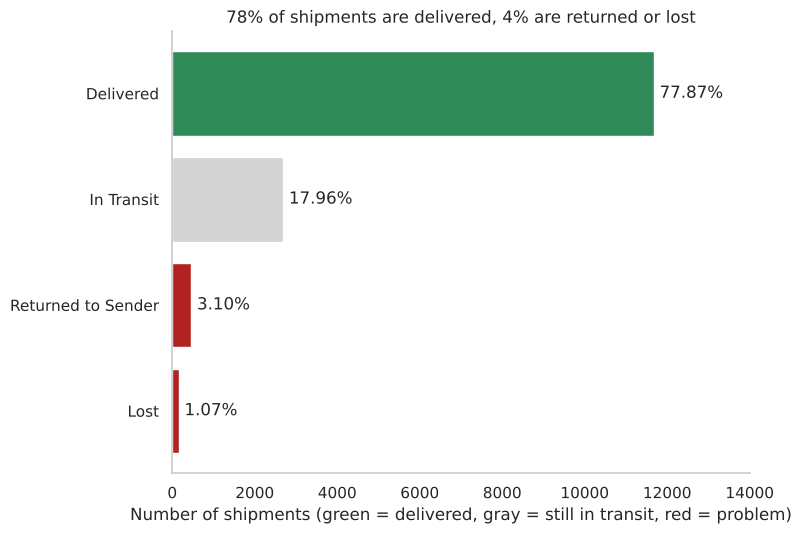

In [116]:
# chart 1: shipment status

fig, ax = plt.subplots(figsize=(8, 5.5))

# bar colors follow the table order: Delivered, In Transit, Returned to Sender, Lost
bar_colors = [green, gray, red, red]
ax.barh(status_table.index, status_table["shipments"], color=bar_colors)

# write the percent at the end of each bar
labels = [f"{p:.2f}%" for p in status_table["percent"]]
ax.bar_label(ax.containers[0], labels=labels, padding=4)

ax.invert_yaxis()   # so Delivered is on top
ax.set_xlim(0, 14000)
ax.set_title("78% of shipments are delivered, 4% are returned or lost")
ax.set_xlabel("Number of shipments (green = delivered, gray = still in transit, red = problem)")
ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(CHARTS / "chart1_shipment_status.png", dpi=150)
plt.show()

**What it shows:** 77.87% of shipments (11,680 of 15,000) were delivered and 17.96% are still in transit. Only 4.17% (626 shipments) were returned to sender or lost.

**So what:** Most deliveries work. The red bars are small, but each lost or returned shipment is a failed delivery that costs us money and a customer.

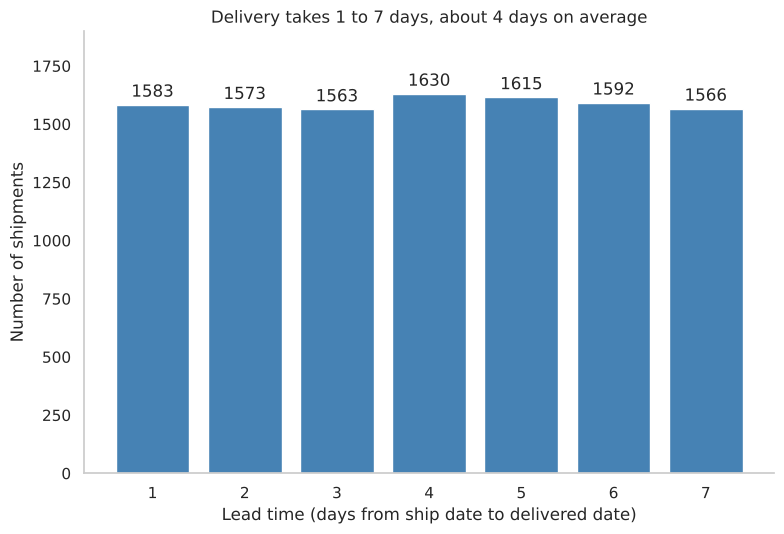

In [117]:
# chart 2: lead time
# count how many shipments took 1 day, 2 days, and so on
lead_counts = shipments["lead_time_days"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.bar(lead_counts.index.astype(int), lead_counts.values, color=blue)
ax.bar_label(ax.containers[0], padding=3)

ax.set_ylim(0, 1900)
ax.set_title("Delivery takes 1 to 7 days, about 4 days on average")
ax.set_xlabel("Lead time (days from ship date to delivered date)")
ax.set_ylabel("Number of shipments")
ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(CHARTS / "chart2_lead_time.png", dpi=150)
plt.show()

**What it shows:** Delivery takes 1 to 7 days, about 4.00 days on average. Every day count has a similar number of shipments (1,563 to 1,630). This uses the 11,122 shipments that have a lead time.

**So what:** Delivery time is predictable, but there is no "fast" group. A 7-day delivery is as common as a 1-day one.

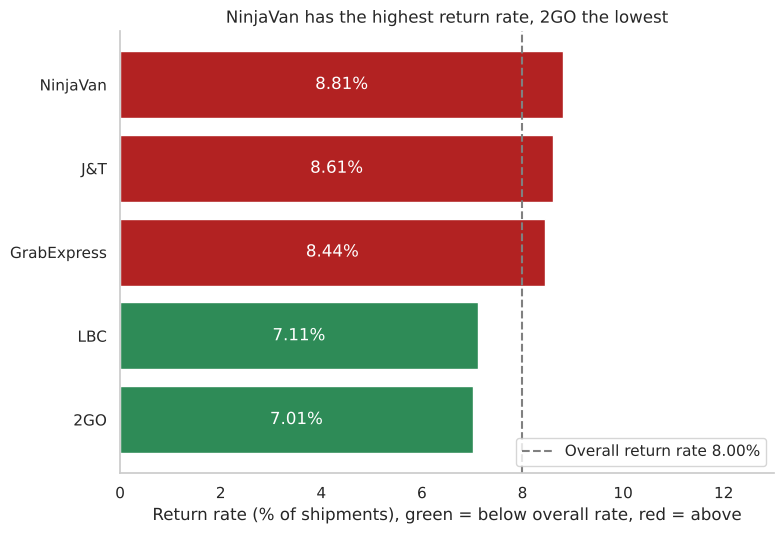

In [118]:
# chart 3: return rate by courier
fig, ax = plt.subplots(figsize=(8, 5.5))

# np.where checks every bar: red if its rate is above the overall rate, green if not
bar_colors = np.where(courier_returns["return_rate_pct"] > return_rate, red, green)
ax.barh(courier_returns.index, courier_returns["return_rate_pct"], color=bar_colors)

# write the rate inside each bar, in white
labels = [f"{r:.2f}%" for r in courier_returns["return_rate_pct"]]
ax.bar_label(ax.containers[0], labels=labels, label_type="center", color="white")

# dashed line = overall return rate of all orders
ax.axvline(return_rate, color="gray", linestyle="--", label="Overall return rate 8.00%")
ax.legend(loc="lower right")

ax.set_xlim(0, 13)
ax.set_title("NinjaVan has the highest return rate, 2GO the lowest")
ax.set_xlabel("Return rate (% of shipments), green = below overall rate, red = above")
ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(CHARTS / "chart3_return_rate_courier.png", dpi=150)
plt.show()

**What it shows:** NinjaVan (8.81%), J&T (8.61%) and GrabExpress (8.44%) are above the overall 8.00% return rate. 2GO (7.01%) and LBC (7.11%) are below it.

**So what:** The couriers deliver at the same speed (3.97 to 4.03 days), so the return rate is what separates them. The gap between the highest and lowest is 1.80 points.

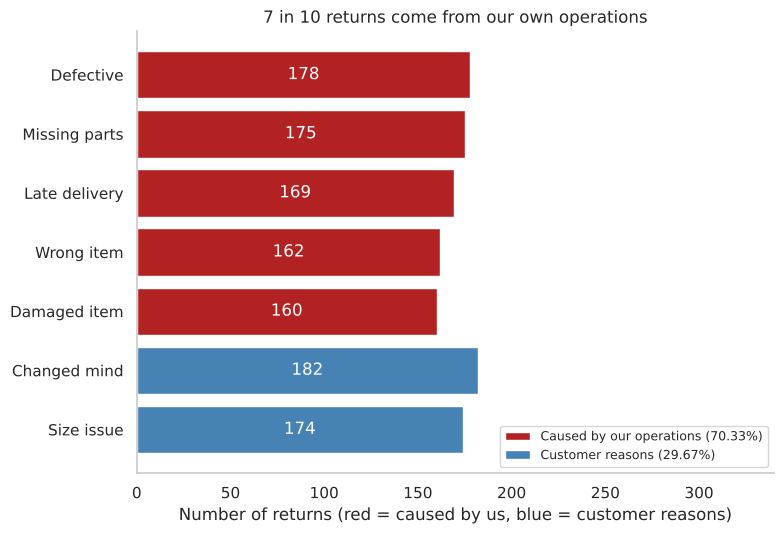

In [119]:
# chart 4: return reasons
# reasons caused by us (operations) and reasons from the customer
our_reasons = ["Defective", "Missing parts", "Late delivery", "Wrong item", "Damaged item"]
customer_reasons = ["Changed mind", "Size issue"]

# pick those rows from my reason table
ours = reason_table.loc[our_reasons]
theirs = reason_table.loc[customer_reasons]

fig, ax = plt.subplots(figsize=(8, 5.5))

# two groups of bars: red for our operations, blue for the customer
ax.barh(ours.index, ours["returns"], color=red, label="Caused by our operations (70.33%)")
ax.barh(theirs.index, theirs["returns"], color=blue, label="Customer reasons (29.67%)")

# write the number inside each bar, in white (container 0 = red bars, container 1 = blue bars)
ax.bar_label(ax.containers[0], label_type="center", color="white")
ax.bar_label(ax.containers[1], label_type="center", color="white")

ax.invert_yaxis()   # so the first reason is on top
ax.set_xlim(0, 340)
ax.legend(loc="lower right", fontsize=9)
ax.set_title("7 in 10 returns come from our own operations")
ax.set_xlabel("Number of returns (red = caused by us, blue = customer reasons)")
ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(CHARTS / "chart4_return_reasons.png", dpi=150)
plt.show()

**What it shows:** 844 of 1,200 returns (70.33%) come from reasons we control: defective, missing parts, late delivery, wrong item and damaged item. The two customer reasons (changed mind, size issue) make up 29.67%.

**So what:** No single reason dominates (each is between 160 and 182 returns). That points to a general quality and packing problem, not one specific fix.

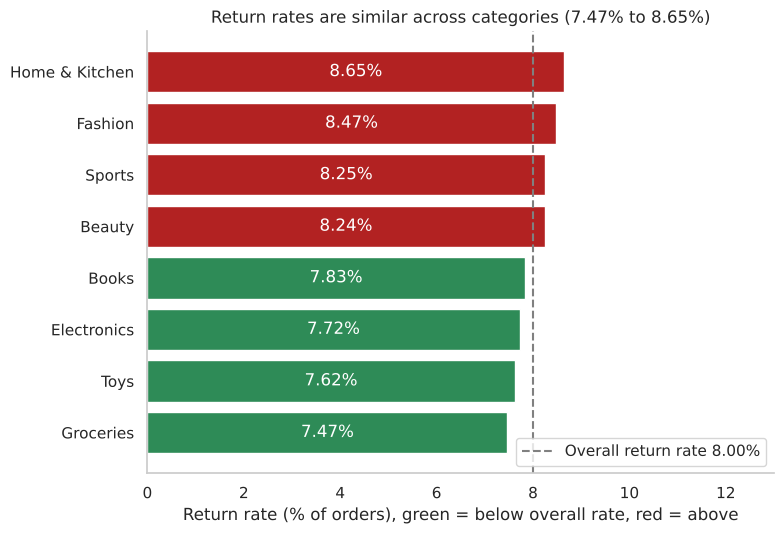

In [120]:
# chart 5: return rate by category
fig, ax = plt.subplots(figsize=(8, 5.5))

# np.where checks every bar: red if its rate is above the overall rate, green if not
bar_colors = np.where(category_returns["return_rate_pct"] > return_rate, red, green)
ax.barh(category_returns.index, category_returns["return_rate_pct"], color=bar_colors)

# write the rate inside each bar, in white
labels = [f"{r:.2f}%" for r in category_returns["return_rate_pct"]]
ax.bar_label(ax.containers[0], labels=labels, label_type="center", color="white")

# dashed line = overall return rate of all orders
ax.axvline(return_rate, color="gray", linestyle="--", label="Overall return rate 8.00%")
ax.legend(loc="lower right")

ax.set_xlim(0, 13)
ax.set_title("Return rates are similar across categories (7.47% to 8.65%)")
ax.set_xlabel("Return rate (% of orders), green = below overall rate, red = above")
ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(CHARTS / "chart5_return_rate_category.png", dpi=150)
plt.show()

**What it shows:** Return rates range from 7.47% (Groceries) to 8.65% (Home & Kitchen). Four categories are above the 8.00% overall rate and four are below it.

**So what:** The gap between categories is small (1.18 points), so category is not the main driver of returns.

In [121]:
# a clean seaborn look for the heatmap (white background, no grid)
sns.set_theme(style="white", font_scale=1.0)

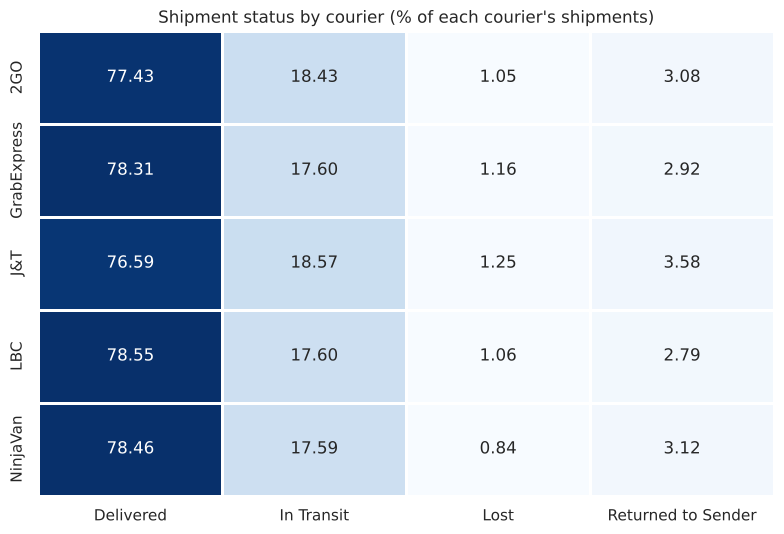

In [122]:
# seaborn heatmap: shipment status by courier (percent of each courier's shipments)
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(status_by_courier, annot=True, fmt=".2f", cmap="Blues", cbar=False, linewidths=2, ax=ax)

ax.set_title("Shipment status by courier (% of each courier's shipments)")
ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()
plt.savefig(CHARTS / "chart6_status_by_courier_heatmap.png", dpi=150)
plt.show()

**What it shows:** Delivered is between 76.59% and 78.55% for every courier. J&T has the lowest delivered rate (76.59%), the highest lost rate (1.25%) and the highest returned to sender rate (3.58%).

**So what:** Couriers are close on most numbers, but J&T is the weakest on every delivery problem, so it is the first courier to review.

## 6. Dashboard

All the key numbers and the main charts on one page, saved at 1920 x 1080 pixels (16:9).

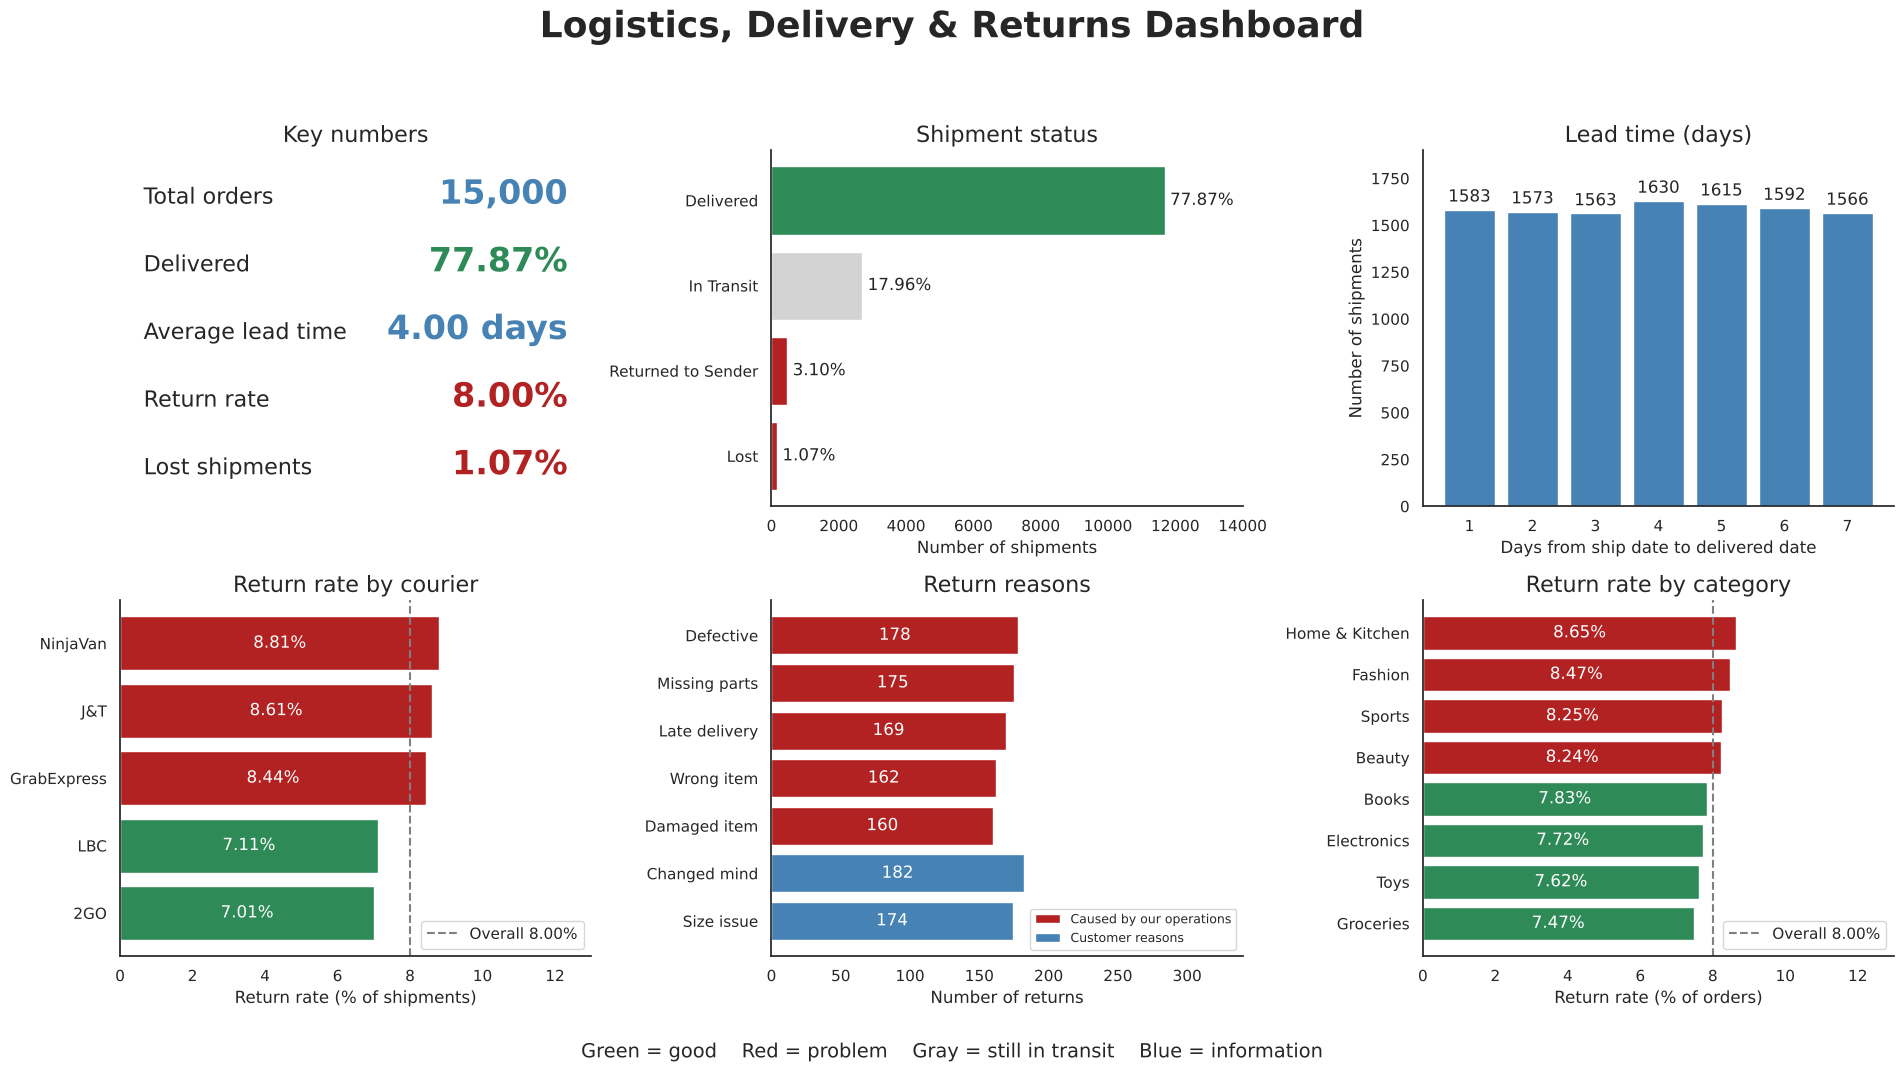

In [123]:
# dashboard: 6 panels in one picture, 1920 x 1080 pixels (16:9)
fig, axes = plt.subplots(2, 3, figsize=(19.2, 10.8))
fig.suptitle("Logistics, Delivery & Returns Dashboard", fontsize=26, fontweight="bold")

# ---------- panel 1 (top left): key numbers ----------
ax = axes[0, 0]
ax.axis("off")
ax.set_title("Key numbers", fontsize=16)

kpi_names = ["Total orders", "Delivered", "Average lead time", "Return rate", "Lost shipments"]
kpi_values = [f"{len(orders):,}",
              f"{status_table.loc['Delivered', 'percent']:.2f}%",
              f"{shipments['lead_time_days'].mean():.2f} days",
              f"{return_rate:.2f}%",
              f"{status_table.loc['Lost', 'percent']:.2f}%"]
kpi_colors = [blue, green, blue, red, red]

for i in range(5):
    y = 0.85 - i * 0.19
    ax.text(0.05, y, kpi_names[i], fontsize=16)
    ax.text(0.95, y, kpi_values[i], fontsize=24, fontweight="bold", color=kpi_colors[i], ha="right")

# ---------- panel 2 (top middle): shipment status ----------
ax = axes[0, 1]
ax.barh(status_table.index, status_table["shipments"], color=[green, gray, red, red])
labels = [f"{p:.2f}%" for p in status_table["percent"]]
ax.bar_label(ax.containers[0], labels=labels, padding=4)
ax.invert_yaxis()
ax.set_xlim(0, 14000)
ax.set_title("Shipment status", fontsize=16)
ax.set_xlabel("Number of shipments")

# ---------- panel 3 (top right): lead time ----------
ax = axes[0, 2]
ax.bar(lead_counts.index.astype(int), lead_counts.values, color=blue)
ax.bar_label(ax.containers[0], padding=3)
ax.set_ylim(0, 1900)
ax.set_title("Lead time (days)", fontsize=16)
ax.set_xlabel("Days from ship date to delivered date")
ax.set_ylabel("Number of shipments")

# ---------- panel 4 (bottom left): return rate by courier ----------
ax = axes[1, 0]
ax.barh(courier_returns.index, courier_returns["return_rate_pct"], color=[green, green, red, red, red])
labels = [f"{r:.2f}%" for r in courier_returns["return_rate_pct"]]
ax.bar_label(ax.containers[0], labels=labels, label_type="center", color="white")
ax.axvline(return_rate, color="gray", linestyle="--", label="Overall 8.00%")
ax.legend(loc="lower right")
ax.set_xlim(0, 13)
ax.set_title("Return rate by courier", fontsize=16)
ax.set_xlabel("Return rate (% of shipments)")

# ---------- panel 5 (bottom middle): return reasons ----------
ax = axes[1, 1]
ax.barh(ours.index, ours["returns"], color=red, label="Caused by our operations")
ax.barh(theirs.index, theirs["returns"], color=blue, label="Customer reasons")
ax.bar_label(ax.containers[0], label_type="center", color="white")
ax.bar_label(ax.containers[1], label_type="center", color="white")
ax.invert_yaxis()
ax.set_xlim(0, 340)
ax.legend(loc="lower right", fontsize=9)
ax.set_title("Return reasons", fontsize=16)
ax.set_xlabel("Number of returns")

# ---------- panel 6 (bottom right): return rate by category ----------
ax = axes[1, 2]
ax.barh(category_returns.index, category_returns["return_rate_pct"], color=[green, green, green, green, red, red, red, red])
labels = [f"{r:.2f}%" for r in category_returns["return_rate_pct"]]
ax.bar_label(ax.containers[0], labels=labels, label_type="center", color="white")
ax.axvline(return_rate, color="gray", linestyle="--", label="Overall 8.00%")
ax.legend(loc="lower right")
ax.set_xlim(0, 13)
ax.set_title("Return rate by category", fontsize=16)
ax.set_xlabel("Return rate (% of orders)")

# ---------- same clean look for every panel ----------
for ax in axes.flatten():
    ax.grid(False)
    ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].spines[["left", "bottom"]].set_visible(False)   # the key numbers panel has no axes

# color key at the bottom
fig.text(0.5, 0.01, "Green = good    Red = problem    Gray = still in transit    Blue = information", ha="center", fontsize=14)

plt.tight_layout(rect=[0, 0.04, 1, 0.94])
plt.savefig(CHARTS / "dashboard_1920x1080.png", dpi=100)
plt.show()

**What it shows:** The key numbers and the five main charts on one page: 77.87% delivered, 4.00 days average lead time, 8.00% return rate and 1.07% lost.

**So what:** Delivery is stable and the main chance to improve is returns, especially the 70.33% that we cause and the three couriers above the average return rate.

## 7. Key insights and recommendations

### Key insights

1. **Most shipments are delivered.** 11,680 of 15,000 shipments (77.87%) were delivered, 17.96% are still in transit, and 4.17% (626 shipments) were returned to sender or lost.
2. **Delivery time is steady.** Delivered shipments take 1 to 7 days, about 4.00 days on average, and each day count has a similar number of shipments (1,563 to 1,630).
3. **Couriers are equal on speed.** Average lead time is between 3.97 and 4.03 days for every courier, so speed does not separate them. Returns do.
4. **8.00% of orders are returned.** 1,200 of 15,000 orders came back.
5. **Three couriers are above the average return rate.** NinjaVan (8.81%), J&T (8.61%) and GrabExpress (8.44%) are above 8.00%. 2GO (7.01%) and LBC (7.11%) are below it. The gap between the highest and lowest is 1.80 points.
6. **J&T has the weakest delivery results.** It has the lowest delivered rate (76.59%) and a lost rate of 1.25%, compared with 0.84% for NinjaVan, the lowest.
7. **Most returns are caused by us.** 844 of 1,200 returns (70.33%) are for reasons tied to our own operations: defective, missing parts, late delivery, wrong item and damaged item. Only 356 (29.67%) are customer reasons (changed mind, size issue).
8. **Category is not the main driver.** Return rates are close across categories, from 7.47% (Groceries) to 8.65% (Home & Kitchen).

### Recommendations

**1. Reduce the returns we cause (top priority)**
- **Based on:** 844 of 1,200 returns (70.33%) come from defective items, missing parts, late delivery, wrong item and damaged item. No single reason dominates (160 to 182 returns each), which points to a general quality and packing problem.
- **Action:** Add a quality and packing check before dispatch: item condition, correct item, complete parts, protective packing. Check the products and suppliers that appear most often in defective and damaged returns.
- **How to track:** Count operations-caused returns every month. For example, cutting them by one third would bring the overall return rate from 8.00% to about 6.1%.

**2. Review the couriers with above-average return rates (top priority)**
- **Based on:** NinjaVan (8.81%), J&T (8.61%) and GrabExpress (8.44%) are above the 8.00% average. 2GO (7.01%) and LBC (7.11%) are below it. All couriers deliver at the same speed (3.97 to 4.03 days), so returns are what separates them.
- **Action:** Build a monthly courier scorecard with return rate, delivered rate, lost rate and lead time. Meet with the three couriers above average. If 2GO and LBC keep lower rates, move more orders to them step by step.
- **How to track:** Compare each courier's return rate with the 8.00% overall rate every month.

**3. Reduce lost and failed deliveries, starting with J&T**
- **Based on:** 626 shipments (4.17%) were lost or returned to sender. J&T has the lowest delivered rate (76.59%), the highest lost rate (1.25%) and the highest returned to sender rate (3.58%).
- **Action:** Raise the J&T results directly with J&T. Set up a claim process for lost parcels and check delivery addresses before dispatch.
- **How to track:** Watch the lost and returned to sender percentages for each courier every month.

**4. Set a delivery time target**
- **Based on:** Delivery takes 1 to 7 days, and about 43% of delivered shipments (4,773 of 11,122) take 5 to 7 days. Late delivery is also the reason for 169 returns (14.08%).
- **Action:** Set a target (for example, 5 days or less) and flag shipments that go past it, so they can be followed up before the customer returns the order.
- **How to track:** The share of shipments delivered within the target, and the number of late delivery returns.

**5. Improve data quality so the next analysis is more reliable**
- **Based on:** 558 delivered shipments have no delivered date, 7,397 shipments are dated before their order date, 583 returns are dated before their order date, and 347 refund records do not match the refund flag (248 and 99).
- **Action:** Make delivered date and refund amount required fields, and check that dates are in a logical order when records are saved.
- **How to track:** The number of records that fail these checks each month, which should go down.

**What not to prioritize:** product category. The return rate only ranges from 7.47% to 8.65% (a 1.18 point gap), so fixing one category will not solve the returns.

### Data notes

- The dataset is synthetic (practice data).
- 558 delivered shipments have no delivered date, so lead time uses 11,122 shipments.
- Some dates do not follow a logical order (for example, many shipments are dated before their order date), so lead time results should be read with care.

## 8. Executive summary

The summary below is saved as `executive_summary.txt` (13 lines).

In [124]:
# executive summary: 8 to 15 lines, saved as a text file

summary = """This project looks at how well we deliver orders and what causes returns, using 15,000 orders from 7 tables.
I cleaned the data first (documented in a 35-line cleaning log, original files untouched), then built the analysis in Python.
77.87% of shipments were delivered, 17.96% are still in transit, and 4.17% were returned to sender or lost.
Delivered shipments take 1 to 7 days, about 4.00 days on average, and all five couriers are within 0.06 days of each other.
1,200 of 15,000 orders were returned, an overall return rate of 8.00%.
NinjaVan (8.81%), J&T (8.61%) and GrabExpress (8.44%) are above the overall rate, while 2GO (7.01%) and LBC (7.11%) are below it.
J&T also has the lowest delivered rate (76.59%) and the highest returned to sender rate (3.58%).
70.33% of returns (844) come from reasons we control: defective, missing parts, late delivery, wrong item and damaged item.
Return rates are similar across categories (7.47% to 8.65%), so category is not the main driver.
Top recommendation 1: add a quality and packing check before dispatch to reduce the returns we cause.
Top recommendation 2: track return rate and lost shipments for each courier every month, and review NinjaVan, J&T and GrabExpress.
Three more recommendations: reduce lost deliveries (starting with J&T), set a delivery time target, and improve date and refund data.
Data note: the data is synthetic and some dates are out of order (for example, shipped before ordered), so lead time results need care."""

# save it next to my notebook
Path("executive_summary.txt").write_text(summary, encoding="utf-8")

# check how many lines the file has
print(len(summary.splitlines()), "lines")

13 lines
